In [1]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def dfs_spanning_tree(G, root=0):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

def gradient_graph(graph : nx.Graph, tree=None, title=None):
    if not tree:
        tree = graph
    # adj_matrix = nx.adjacency_matrix(tree, nodelist=range(tree.number_of_nodes())).todense()
    adj_matrix = nx.adjacency_matrix(tree).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted = np.argsort(fiedler)

    fiedler_dict = {}
    n = len(graph.nodes())
    fiedler_dict = {sorted[i] : fiedler[sorted[i]] for i in range(n)}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()

def relabel_02n(G):
    # Create a mapping from old labels to new integer labels
    old_labels = list(G.nodes())
    mapping = {old_label: new_label for new_label, old_label in enumerate(old_labels)}
    
    # Relabel the graph
    G_relabelled = nx.relabel_nodes(G, mapping, copy=True)
    
    # Store the old labels as node attributes
    for new_label, old_label in mapping.items():
        G_relabelled.nodes[old_label]['old_label'] = new_label

    mapping = {new_label: old_label for new_label, old_label in enumerate(old_labels)}
    return G_relabelled, mapping  # Also return the mapping for reference

def graph_fiedler_sort(graph):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

# def initial_layout(graph : nx.Graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None):
#     num_nodes = graph.number_of_nodes()
#     sorted_nodes = graph_fiedler_sort(graph)

#     if topology=='chain':
#         chain = find_linear_chain(backend, num_nodes)
#     else:
#         G = get_coupling_graph(backend)

#         if not root_on_backend:
#             root_on_backend = backend.num_qubits//2
#         tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
#         order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))

#     if how=='fiedler':
#         if topology=='chain':
#             logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
#         else:
#             logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
#     elif how=='trivial':
#         logical_to_physical = {i: i for i in range(num_nodes)}
#     elif how=='random':
#         random_map = list(range(num_nodes))
#         random.seed(0)
#         random.shuffle(random_map)
#         logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
#     else:
#         print("Invalid starting layout!!!")
#         return -1

#     return logical_to_physical

import networkx as nx
import random

def bfs_subgraph_clusters(H, n_clusters, cluster_size, start_node=None):
    """
    Partition a hardware graph H into n_clusters disjoint BFS-based regions
    of size `cluster_size`.

    Parameters
    ----------
    H : networkx.Graph
        The hardware topology (undirected or directed).
    n_clusters : int
        Number of logical clusters (same number of hardware BFS regions).
    cluster_size : int
        Number of nodes (qubits) per BFS region.
    start_node : int, optional
        Starting node for the first BFS cluster.

    Returns
    -------
    regions : list[set]
        List of sets, each containing the nodes in one BFS cluster.
    """
    visited = set()
    regions = []

    # Start BFS from central nodes if not provided
    if start_node is None:
        start_node = max(H.nodes, key=lambda x: H.degree(x))
    queue = [start_node]

    i=0
    while i < n_clusters:
        # Find next unvisited start node
        while queue and queue[0] in visited:
            queue.pop(0)
        # print(i,queue,visited)
        if not queue:
            # Fallback: pick next unvisited node (most connected)
            unvisited = [n for n in H.nodes if n not in visited]
            if not unvisited:
                break
            next_root = max(unvisited, key=lambda x: H.degree(x))
            queue = [next_root]
        root = queue[0]

        # Build BFS cluster
        q = [root]
        cluster_nodes = set()
        visited.add(root)

        while q and len(cluster_nodes) < cluster_size:
            node = q.pop(0)
            cluster_nodes.add(node)
            visited.add(node)
            for nbr in H.neighbors(node):
                if nbr not in visited:
                    q.append(nbr)
                    queue.append(nbr)

        if len(cluster_nodes) == cluster_size:
            regions.append(cluster_nodes)
            i+=1

    return regions

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from scipy.spatial.distance import cdist

def cluster_embedding(nodes, Y, num_clusters=None, method='kmeans', eps=0.1, min_samples=3, plot=False):
    if method == 'kmeans':
        if num_clusters is None:
            num_clusters = int(np.sqrt(len(nodes)))  # simple heuristic
        clustering = KMeans(n_clusters=num_clusters, random_state=0).fit(Y)
        labels = clustering.labels_
        centroids_array = clustering.cluster_centers_
    elif method == 'dbscan':
        clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(Y)
        labels = clustering.labels_

        # Compute centroids manually (ignore noise label = -1)
        unique_labels = [l for l in set(labels) if l != -1]
        centroids_array = np.array([
            Y[labels == l].mean(axis=0) for l in unique_labels
        ])
    else:
        raise ValueError("method must be 'kmeans' or 'dbscan'")

    # Visualization
    if plot:
        plt.figure(figsize=(6,5))
        scatter = plt.scatter(Y[:, 0], Y[:, 1], c=labels, cmap='tab10', s=100)
        for i, node in enumerate(nodes):
            plt.text(Y[i, 0], Y[i, 1], str(node), fontsize=8, ha='center', va='center')
        plt.scatter(centroids_array[:,0], centroids_array[:,1], c='black', marker='x', s=100, label='Centroids')
        plt.title("Spectral/MDS Embedding with Clusters")
        plt.colorbar(scatter, label='Cluster ID')
        plt.legend()
        plt.show()

    # Build cluster dictionary
    clusters = {}
    for node, label in zip(nodes, labels):
        clusters.setdefault(label, []).append(node)

    # Store centroids in a dict
    centroids = {i: centroids_array[i] for i in range(len(centroids_array))}

    return clusters, centroids

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

def order_clusters_by_pca(centroids, plot=False):
    cluster_ids = list(centroids.keys())
    X = np.array([centroids[cid] for cid in cluster_ids])

    # Project centroids into 2D space
    pca = PCA(n_components=2)
    X_2d = pca.fit_transform(X)

    # Store coordinates
    pca_coords = {cid: X_2d[i] for i, cid in enumerate(cluster_ids)}

    # Compute distances in 2D PCA space
    from scipy.spatial.distance import cdist
    dist_matrix = cdist(X_2d, X_2d)

    # Greedy ordering based on nearest-neighbor chain
    ordered = [0]  # start from first cluster
    visited = set(ordered)
    while len(ordered) < len(cluster_ids):
        last = ordered[-1]
        next_cand = np.argmin([dist_matrix[last, j] if j not in visited else np.inf
                               for j in range(len(cluster_ids))])
        ordered.append(next_cand)
        visited.add(next_cand)

    ordered_clusters = [cluster_ids[i] for i in ordered]

    # Visualization
    if plot:
        plt.figure(figsize=(5, 5))
        for i, cid in enumerate(cluster_ids):
            plt.scatter(X_2d[i, 0], X_2d[i, 1], label=f"Cluster {cid}")
            plt.text(X_2d[i, 0], X_2d[i, 1], f"{cid}", fontsize=10, ha='center', va='center')
        plt.plot(X_2d[ordered, 0], X_2d[ordered, 1], 'k--', alpha=0.5)
        plt.title("Cluster Centroids (PCA 2D Projection)")
        plt.legend()
        plt.show()

    return ordered_clusters, pca_coords
import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def graph_laplacian_embedding(G, k=2, alpha=0.95):
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        adj_matrix = nx.adjacency_matrix(G, nodelist=G.nodes()).todense()
        L = laplacian(adj_matrix)
        vals, vecs = eigh(L)
        X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None

def initial_layout(graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None):
    num_nodes = graph.number_of_nodes()
    n = int(np.sqrt(num_nodes))
    if how=='fiedler':
        sorted_nodes = graph_fiedler_sort(graph)

        if topology=='chain':
            chain = find_linear_chain(backend, num_nodes)
        else:
            G = get_coupling_graph(backend)

            if not root_on_backend:
                root_on_backend = backend.num_qubits//2
            tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
            degrees = tree_layout.degree()
        
            # Find the node with the minimum degree
            min_node = min(degrees, key=lambda x: x[1])[0]

            if topology=='tree_dfs':
                order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))
    elif how=='clustered':
        G = get_coupling_graph(backend)

        if not root_on_backend:
            root_on_backend = backend.num_qubits//2
        hclusters = bfs_subgraph_clusters(G, n_clusters=n, cluster_size=n, start_node=root_on_backend)

        order = []
        for cluster in hclusters:
            order+=cluster
        # tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
        # order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))
        logical_embedding = graph_laplacian_embedding(graph, k=n-1, alpha=0.95)
        lclusters, centroids = cluster_embedding(nodes=list(range(n*n)), Y=logical_embedding, num_clusters=n)
        ordered_clusters, pca_coords = order_clusters_by_pca(centroids, plot=False)

        sorted_nodes = []
        for cid in ordered_clusters:
            sorted_nodes += lclusters[cid]
        # print(sorted_nodes)
        # sorted_nodes = list(range(num_nodes))

    if how not in ['trivial', 'random']:
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit

In [2]:
def return_ops(backend, graph_type='reg', param=4, tree_type='rand', average_over=5, node_list=list(range(10,101,2)), reps=2, topology='tree_dfs', opt_level=3, op_name='ecr', use_custom=True, stop_after_routing=False):
    swaps = {'means': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]},
             'stddevs': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':[], 'fied':[], 'triv':[], 'rand':[]}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = nx.barabasi_albert_graph(n=n, m=param, seed=0)
        if tree_type=='rand':
            tree = nx.random_spanning_tree(graph, seed=i)
        else:
            tree = dfs_spanning_tree(graph, root=0)
        fiedler_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology)
        gen = gen_QAOA_circuit(graph, reps=reps)
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, fiedler_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        # swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(tree, backend=backend, how='trivial')
        # swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(tree, backend=backend, how='random')
        # swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            swap_avg['fied'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['triv'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['sabre'].append(func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0))
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['means']['SABRE'].append(np.mean(swap_avg['sabre']))
        swaps['stddevs']['SABRE'].append(np.std(swap_avg['sabre']))

        swaps['means']['Proposed'].append(np.mean(swap_avg['fied']))
        swaps['stddevs']['Proposed'].append(np.std(swap_avg['fied']))

        swaps['means']['Trivial'].append(np.mean(swap_avg['triv']))
        swaps['stddevs']['Trivial'].append(np.std(swap_avg['triv']))

    return swaps

In [3]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
backend = FakeFez()
# backend = FakeTorino()

In [159]:
import warnings
warnings.filterwarnings("ignore")

In [164]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=10, node_list=nodes_reg,
                         topology='tree', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

In [165]:
for param in params_reg:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes_reg, swaps_reg[param][s], label=s)

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title(f"SWAPs vs Number of Nodes\nFor {param}-regular graphs")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend( fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

KeyError: 'Proposed'

<Figure size 800x500 with 0 Axes>

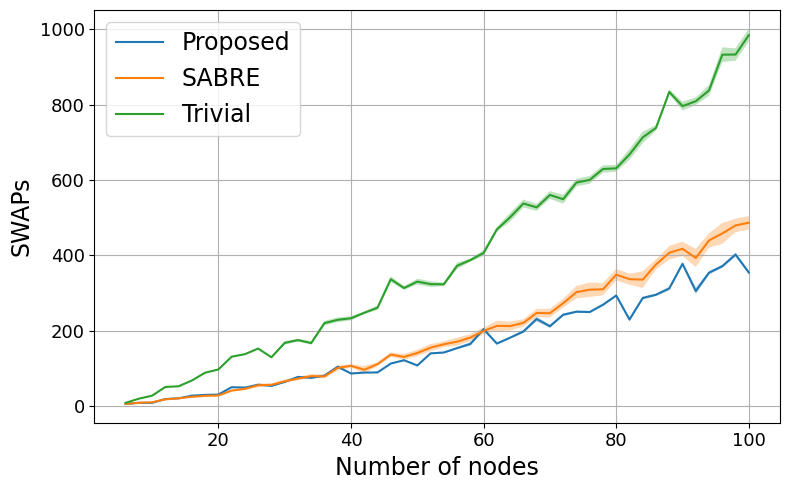

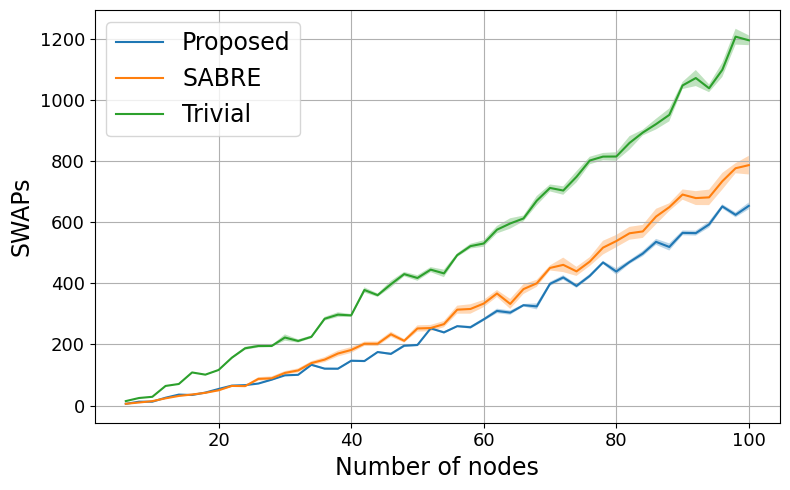

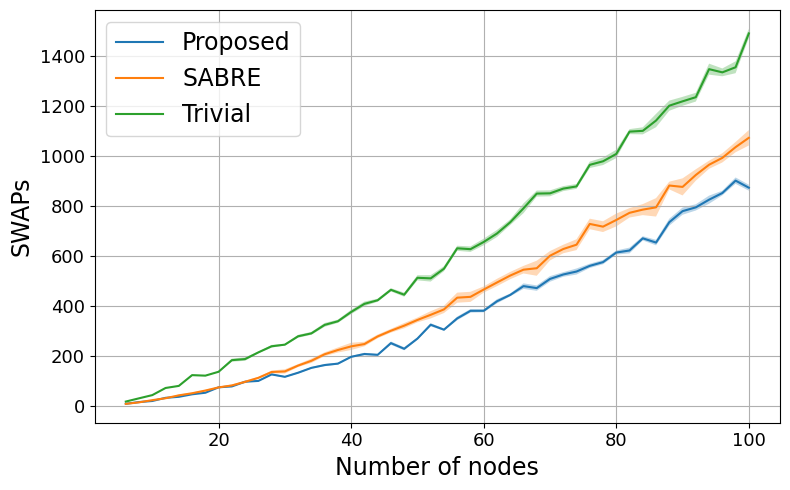

In [180]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

In [166]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param, tree_type='dfs',
                         average_over=10, node_list=nodes_ba,
                         topology='tree', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

In [167]:
# nodes = list(range(6, 101, 2))
# params = list(range(3,6,1))
for param in params_ba:
    # Create a new plot for each value of param
    plt.figure(figsize=(8, 5))

    for s in strategies:
        if s!='Random':
            plt.plot(nodes_ba, swaps_ba[param][s], label=s)

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title(f"SWAPs vs Number of Nodes\nFor {param}-regular graphs")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend( fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

KeyError: 'Proposed'

<Figure size 800x500 with 0 Axes>

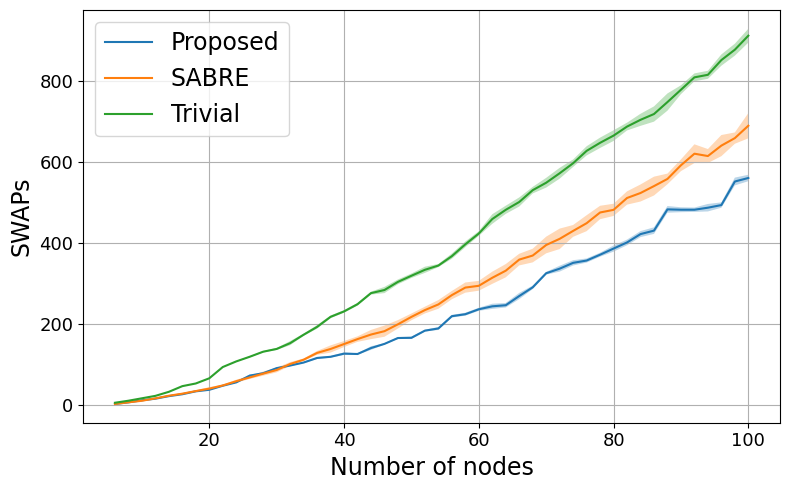

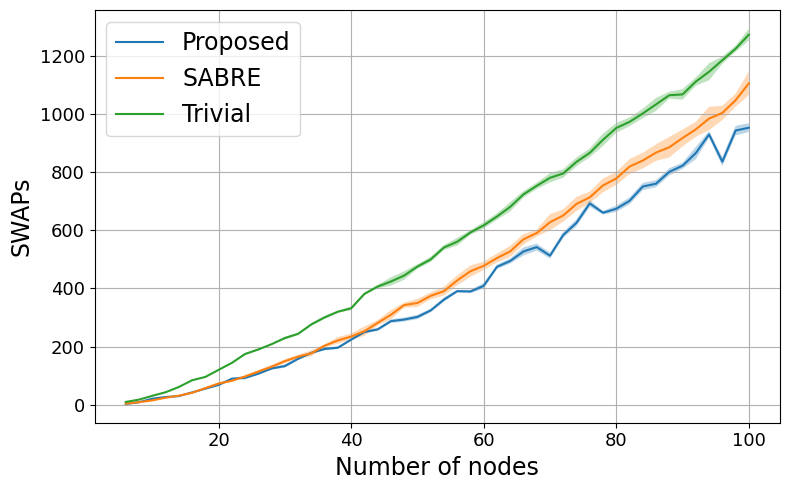

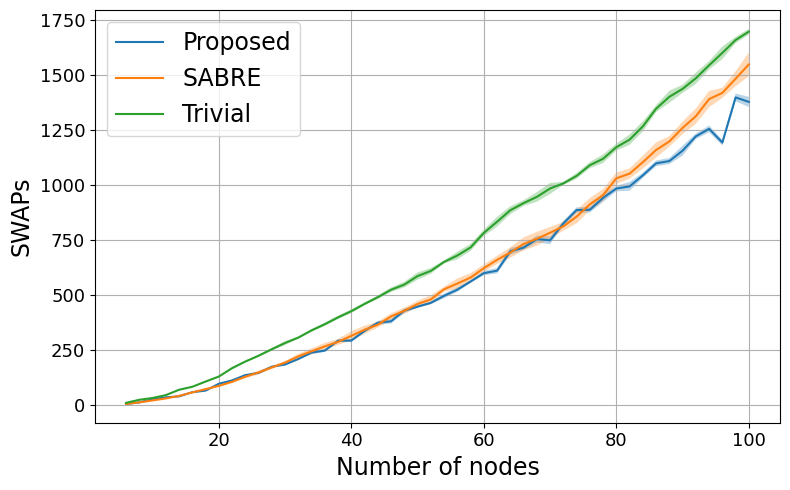

In [179]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()
